# PS-01 · Banana Leaf Spot Disease Classification
### Complete, reproducible TensorFlow/Keras notebook — OriginalSet only

**Task:** classify a smartphone banana-leaf image as **Healthy, Sigatoka, Cordana, or Pestalotiopsis**. Primary selection metric: **validation macro F1**; final reporting: held-out test accuracy, macro F1, per-class precision/recall/F1, and confusion matrix.

**Read before running**
- Open in Google Colab, select **Runtime → Change runtime type → T4 GPU**, then run cells from top to bottom. CPU is supported but slower.
- The assignment says to use the **faculty-provided local copy**. Set `DATA_SOURCE="local"` and `LOCAL_DATA_PATH` when you have it. The default official-download mode is for when that copy is unavailable; confirm permission with your instructor.
- Use **only OriginalSet**. Never combine the publisher's AugmentedSet with these images. Online augmentation is applied to training batches only.
- This is an **untrained notebook**: no accuracy, plots, training histories, or model results have been invented. All experiment outputs are computed when you run it.
- Before submission, enter your details below, review every cell, run fully, save the notebook **with outputs**, and upload it to GitHub. Understand the code for the viva and declare AI assistance.

The notebook follows the supplied instructions: EDA → leakage audit → saved group-aware train/validation/test split → CNN baseline → ImageNet transfer learning → class-weight ablation → one locked test-evaluation round → misclassifications/Grad-CAM → reproducibility and report-ready exports.

**Validation performed before delivery:** notebook-format and Python-syntax checks passed. The acquisition/audit/split cells were exercised on the official version-1 originals, including a repeat run of the saved split check. Full TensorFlow training and Grad-CAM execution were **not** completed in the preparation environment; run the complete notebook in Colab and review any environment-specific issues. No training/test outputs are embedded.

**Verified original-archive audit (not model results):** 937 readable originals; 2 images excluded for an exact-content conflicting-label pair; 38 additional same-label repeats removed; 897 retained. With the default protocol the tested source folder produced 538 train, 180 validation and 179 test images. Actual split membership can depend on path names and library versions; saved manifests, not these reference numbers, are authoritative for your own run.

## 1. Problem, evidence and design

**Success criterion:** among the predeclared candidates, choose the highest validation macro F1, then evaluate on the untouched test split. Macro F1 gives each class equal weight, unlike accuracy, which can hide weak minority-class performance. No target accuracy is promised.

The official dataset has **937 original RGB images, 224 × 224**: Cordana 162, Healthy 129, Pestalotiopsis 173, Sigatoka 473. These are expected source counts, not hard-coded observed results. Runtime cells verify the files actually loaded.

**Important data issue:** inspection of the version-1 original archive found exact repeated image content, including conflicting labels. Therefore this notebook audits decoded RGB pixels, quarantines exact label conflicts, removes repeated same-label content, and groups remaining near-identical images before splitting. Near-similarity is a heuristic, not proof of a shared plant or patient identity. Images removed during auditing remain documented in CSV files; the report must state the number actually used.

**Predeclared experiments**

| Candidate | Architecture | Training augmentation | Class weights | Purpose |
|---|---|---|---|---|
| scratch_cnn | Compact 3-block CNN | Yes | No | From-scratch reference |
| mobilenet_unweighted | ImageNet MobileNetV2; head + limited fine-tuning | Yes | No | Transfer-learning baseline |
| mobilenet_weighted | Same MobileNetV2 schedule and initialization | Yes | Training-only balanced weights | Isolated imbalance-handling ablation |

Transfer learning is suitable for a small dataset; MobileNetV2 is a compact candidate, not a claim of proven smartphone readiness. The two MobileNet experiments use the same seed, architecture, augmentation and schedule. Early stopping can yield different numbers of epochs; training time and epochs are logged. Do not claim class weights help unless the measured evidence supports it.

Sources: [official BananaLSD v1](https://data.mendeley.com/datasets/9tb7k297ff/1), [dataset paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC10562173/), [Keras transfer learning](https://keras.io/guides/transfer_learning/), [MobileNetV2 preprocessing](https://keras.io/api/applications/mobilenet/mobilenet_models/), [TensorFlow determinism](https://www.tensorflow.org/api_docs/python/tf/config/experimental/enable_op_determinism).

## 2. Install dependencies
Run this cell once. Existing compatible Colab packages are reused. If Colab requests a restart after installation, restart the runtime and continue from the imports cell. The exact resolved versions are saved with the outputs; exact cross-hardware or cross-version equality is not guaranteed.

In [1]:
%pip -q install "tensorflow>=2.16,<2.21" "scikit-learn>=1.4,<1.7" "pandas>=2.1,<3" "matplotlib>=3.8,<3.11" "Pillow>=10,<13" "requests>=2.31,<3" "tqdm>=4.66,<5"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.8/620.8 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 63.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tf-keras 2.21.0 requires tensorflow<2.22,>=2.21, but you have tensorflow 2.20.0 which is incompatible.
tensorflow-text 2.21.1 requires tensorflow<2.22,>=2.21.0, but you have tensorflow 2.20.0 which is incompatible.
ydf-tf 2.21.0 requires tensorflow==2.21.0, but you have tensorflow 2.20.0 which is incompatible.


In [2]:
import os
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import sys, json, hashlib, random, platform, time, zipfile, re, shutil, subprocess
from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import requests
from tqdm.auto import tqdm
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 10})
print("Python:", platform.python_version(), "TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("CPU detected. For faster training, use a Colab GPU runtime.")

Python: 3.13.15 TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Your details and experiment settings
Edit only this cell for paths and identity. No dataset upload is required in `official_download` mode. For a local zip, set `LOCAL_DATA_PATH` to that zip; for extracted data, point at `OriginalSet` or its parent. If a renamed class-root folder lacks an `OriginalSet` ancestor, explicitly set `CONFIRM_LOCAL_IS_ORIGINAL=True` only after checking it. Never use that flag for AugmentedSet.

The 5-fold outer / 4-fold inner **stratified group** construction produces approximately **60% train / 20% validation / 20% test**. Actual counts vary with similarity groups and are reported. Do not change hyperparameters in response to test results.

In [3]:
STUDENT_NAME = "Kamisetty Koushik"  # Edit if needed.
REGISTER_NO = "RA2311026050059"      # REQUIRED before submission.
SECTION = "AIML-B"
GITHUB_NOTEBOOK_URL = "https://github.com/koushik5636N/DL-CBL"
PS_NO = "PS01"

DATA_SOURCE = "official_download"  # "local" is preferred when faculty data is available.
LOCAL_DATA_PATH = ""                # e.g. "/content/drive/MyDrive/BananaLSD/OriginalSet"
CONFIRM_LOCAL_IS_ORIGINAL = False

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SCRATCH_EPOCHS = 20
HEAD_EPOCHS = 12
FINETUNE_EPOCHS = 12
PATIENCE = 4
HEAD_LR = 1e-3
FINETUNE_LR = 1e-5
FINETUNE_LAST_LAYERS = 30
DROPOUT = 0.30
NEAR_DUPLICATE_DHASH_DISTANCE = 4  # Predeclared heuristic, not a semantic identity test.
OUTER_FOLDS, INNER_FOLDS = 5, 4

CLASS_NAMES = ["Healthy", "Sigatoka", "Cordana", "Pestalotiopsis"]
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
EXPECTED_COUNTS = {"Healthy": 129, "Sigatoka": 473, "Cordana": 162, "Pestalotiopsis": 173}
DATASET_URL = "https://data.mendeley.com/datasets/9tb7k297ff/1"
DOWNLOAD_URL = "https://data.mendeley.com/public-api/zip/9tb7k297ff/download/1"
EXPECTED_ARCHIVE_SHA256 = "420523152c2b65c3f116c072cf95017733e9b8cd0cd01b7f667c588ca81dc85d"

WORK_ROOT = Path("/content/banana_ps01") if Path("/content").exists() else Path.cwd() / "banana_ps01"
DATA_HOME = WORK_ROOT / "data"
safe_register = re.sub(r"[^A-Za-z0-9_-]", "_", REGISTER_NO)
EXPORT_ROOT = WORK_ROOT / "outputs" / f"{safe_register}_{PS_NO}"
for folder in (DATA_HOME, EXPORT_ROOT):
    folder.mkdir(parents=True, exist_ok=True)

def reset_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

reset_seeds()
tf.config.experimental.enable_op_determinism()
for device in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(device, True)
    except RuntimeError:
        pass

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")

print("Output root:", EXPORT_ROOT)

Output root: /content/banana_ps01/outputs/RA2311026050059_PS01


## 4. Acquire OriginalSet safely
The official archive may include both sets, but only image members under **OriginalSet** are extracted. The official v1 archive SHA-256 is checked. No hard-coded temporary signed S3 URL is used. If the server blocks an automated request, download through the dataset page, choose `local`, and rerun this cell.

For Drive data in Colab, mount Drive manually first if needed: `from google.colab import drive; drive.mount('/content/drive')`. The downloader does not require Drive.

In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def class_from_folder(name):
    key = re.sub(r"[^a-z]", "", name.lower())
    if "healthy" in key: return "Healthy"
    if "sigatoka" in key: return "Sigatoka"
    if "cordana" in key: return "Cordana"
    if "pestalotiopsis" in key: return "Pestalotiopsis"
    return None

def original_root(path):
    path = Path(path).expanduser().resolve()
    if not path.is_dir():
        raise FileNotFoundError(path)
    if any("augment" in p.lower() for p in path.parts):
        raise ValueError("AugmentedSet is forbidden. Select OriginalSet.")
    roots = [path] if "original" in path.name.lower() else []
    roots += sorted(p for p in path.rglob("*") if p.is_dir() and "original" in p.name.lower()
                    and not any("augment" in q.lower() for q in p.parts))
    if not roots and CONFIRM_LOCAL_IS_ORIGINAL:
        roots = [path]
    valid = []
    for root in roots:
        labels = {class_from_folder(p.name) for p in root.iterdir() if p.is_dir()}
        if set(CLASS_NAMES).issubset(labels):
            valid.append(root)
    valid = sorted(set(valid), key=str)
    if len(valid) != 1:
        raise ValueError(f"Expected one OriginalSet root; found {len(valid)}. Point LOCAL_DATA_PATH directly at it.")
    return valid[0]

def extract_original_images(archive, destination):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    count = 0
    with zipfile.ZipFile(archive) as z:
        for member in z.infolist():
            parts = Path(member.filename.replace("\\", "/")).parts
            original_positions = [i for i, part in enumerate(parts) if "original" in part.lower()]
            if member.is_dir() or not original_positions or Path(member.filename).suffix.lower() not in IMAGE_EXTENSIONS:
                continue
            if any("augment" in part.lower() for part in parts):
                continue
            start = original_positions[-1]
            tail = parts[start + 1:]
            if len(tail) < 2 or any(part in {"..", ".", ""} for part in tail):
                raise ValueError("Unexpected archive path; refusing unsafe extraction.")
            label = class_from_folder(tail[0])
            if label is None:
                continue
            target = destination / label / Path(*tail[1:])
            if not target.resolve().is_relative_to(destination.resolve()):
                raise ValueError("Unsafe archive path.")
            if member.file_size > 30 * 1024 * 1024:
                raise ValueError("Unexpectedly large image in archive.")
            target.parent.mkdir(parents=True, exist_ok=True)
            with z.open(member) as src, open(target, "wb") as dst:
                shutil.copyfileobj(src, dst)
            count += 1
    if count == 0:
        raise ValueError("No OriginalSet images found. Extract the source manually and select its OriginalSet directory.")
    print("Extracted original image files:", count)
    return destination.resolve()

if DATA_SOURCE == "local":
    if not LOCAL_DATA_PATH:
        raise ValueError("Set LOCAL_DATA_PATH to the faculty copy (OriginalSet, its parent, or a zip).")
    source = Path(LOCAL_DATA_PATH).expanduser()
    if source.suffix.lower() == ".zip":
        extraction = DATA_HOME / ("local_" + sha256_file(source)[:12]) / "OriginalSet"
        DATA_ROOT = extract_original_images(source, extraction)
    else:
        DATA_ROOT = original_root(source)
elif DATA_SOURCE == "official_download":
    archive = DATA_HOME / "BananaLSD_v1.zip"
    if not archive.exists() or sha256_file(archive) != EXPECTED_ARCHIVE_SHA256:
        temporary = archive.with_suffix(".partial")
        try:
            with requests.get(DOWNLOAD_URL, stream=True, timeout=(30, 180)) as response:
                response.raise_for_status()
                with open(temporary, "wb") as f:
                    for chunk in tqdm(response.iter_content(1024 * 1024), desc="Downloading official v1", unit="MB"):
                        if chunk: f.write(chunk)
            if not zipfile.is_zipfile(temporary):
                raise RuntimeError("Server returned a non-zip response.")
            if sha256_file(temporary) != EXPECTED_ARCHIVE_SHA256:
                raise RuntimeError("Archive differs from verified v1. Inspect it manually; do not silently continue.")
            temporary.replace(archive)
        except Exception as exc:
            raise RuntimeError("Automatic download failed. Download manually from the dataset page, set local mode and a zip path.") from exc
    DATA_ROOT = extract_original_images(archive, DATA_HOME / "official_v1" / "OriginalSet")
else:
    raise ValueError("DATA_SOURCE must be 'local' or 'official_download'.")

assert not any("augment" in p.lower() for p in DATA_ROOT.parts)
print("Using only:", DATA_ROOT)

Extracted original image files: 937
Using only: /content/banana_ps01/data/official_v1/OriginalSet


## 5. EDA and integrity audit
A **pixel hash** includes RGB dimensions and decoded bytes, so identical image content can be detected even if metadata differs. Cross-label exact duplicates are quarantined, not relabelled. Same-label exact duplicates retain one deterministic representative. Other unreadable images are logged, never silently ignored. No test set exists yet at this stage.

Auditing originals:   0%|          | 0/941 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py:887: UserWarning: Image appears to be a malformed MPO file, it will be interpreted as a base JPEG file
  warnings.warn(


,Expected official original,Loaded original,After audit
Healthy,129,129,90
Sigatoka,473,473,473
Cordana,162,162,162
Pestalotiopsis,173,173,172


Readable originals: 937; unreadable: 0
Quarantined conflicting-label images: 2; removed repeats: 38; used: 897
Observed dimensions: {(224, 224): 937}


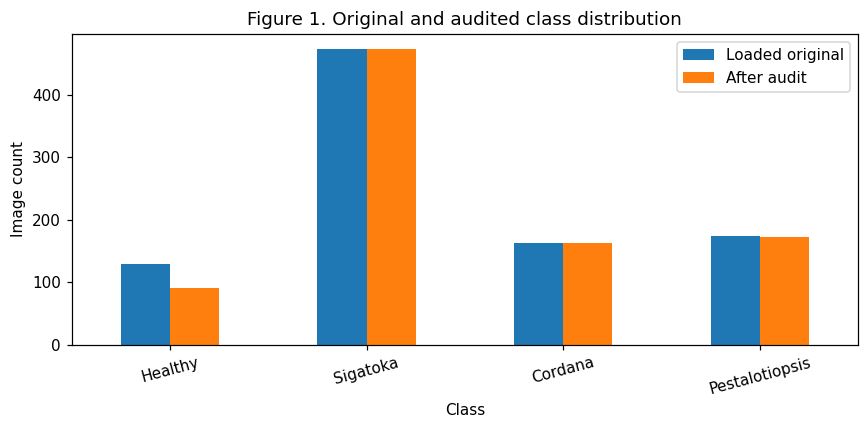

In [5]:
raw_rows, corrupt_rows = [], []
for path in tqdm(sorted(DATA_ROOT.rglob("*")), desc="Auditing originals"):
    if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue
    rel = path.relative_to(DATA_ROOT)
    if len(rel.parts) < 2 or any("augment" in p.lower() for p in rel.parts):
        raise ValueError(f"Unexpected non-original image path: {rel}")
    label = class_from_folder(rel.parts[0])
    if label is None:
        raise ValueError(f"Unknown class directory: {rel.parts[0]}")
    try:
        with Image.open(path) as image:
            rgb = ImageOps.exif_transpose(image).convert("RGB")
            rgb.load()
            pixel_hash = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
            gray = np.asarray(rgb.resize((9, 8)).convert("L"))
            bits = (gray[:, 1:] > gray[:, :-1]).ravel()
            dhash = format(int("".join("1" if b else "0" for b in bits), 2), "016x")
            width, height = rgb.size
        raw_rows.append({"path": str(path.resolve()), "relative_path": str(rel), "class_name": label,
                         "label": CLASS_TO_ID[label], "width": width, "height": height,
                         "byte_sha256": sha256_file(path), "pixel_sha256": pixel_hash, "dhash": dhash})
    except Exception as exc:
        corrupt_rows.append({"relative_path": str(rel), "error": repr(exc)})
raw_df = pd.DataFrame(raw_rows).sort_values("relative_path").reset_index(drop=True)
if raw_df.empty:
    raise ValueError("No readable original images found.")
raw_df.to_csv(EXPORT_ROOT / "raw_image_manifest.csv", index=False)
pd.DataFrame(corrupt_rows, columns=["relative_path", "error"]).to_csv(EXPORT_ROOT / "corrupt_images.csv", index=False)

label_count_per_hash = raw_df.groupby("pixel_sha256")["label"].nunique()
conflict_hashes = set(label_count_per_hash[label_count_per_hash > 1].index)
conflicts = raw_df[raw_df.pixel_sha256.isin(conflict_hashes)].copy()
conflicts.to_csv(EXPORT_ROOT / "quarantined_label_conflicts.csv", index=False)
consistent = raw_df[~raw_df.pixel_sha256.isin(conflict_hashes)].copy()
repeats = consistent[consistent.duplicated("pixel_sha256", keep="first")].copy()
repeats.to_csv(EXPORT_ROOT / "removed_exact_repeats.csv", index=False)
df = consistent.drop_duplicates("pixel_sha256", keep="first").reset_index(drop=True)

counts = pd.DataFrame({"Expected official original": pd.Series(EXPECTED_COUNTS),
                       "Loaded original": raw_df.class_name.value_counts(),
                       "After audit": df.class_name.value_counts()}).reindex(CLASS_NAMES).fillna(0).astype(int)
counts.to_csv(EXPORT_ROOT / "class_counts.csv", index_label="class_name")
display(counts)
print(f"Readable originals: {len(raw_df)}; unreadable: {len(corrupt_rows)}")
print(f"Quarantined conflicting-label images: {len(conflicts)}; removed repeats: {len(repeats)}; used: {len(df)}")
print("Observed dimensions:", raw_df.groupby(["width", "height"]).size().to_dict())
if counts["Loaded original"].to_dict() != EXPECTED_COUNTS:
    print("NOTE: loaded counts differ from official full set. Check whether faculty supplied a subset; report actual sizes.")
if set(df.class_name) != set(CLASS_NAMES):
    raise ValueError("All four classes are required.")
fig, ax = plt.subplots(figsize=(8, 4))
counts[["Loaded original", "After audit"]].plot.bar(ax=ax, rot=15)
ax.set(xlabel="Class", ylabel="Image count", title="Figure 1. Original and audited class distribution")
fig.tight_layout(); fig.savefig(EXPORT_ROOT / "fig01_class_distribution.png"); plt.show()

## 6. Near-duplicate groups and saved split
A 64-bit difference-hash (dHash) Hamming distance of at most 4 flags visually similar images. Connected components are kept entirely within one split, including any unresolved cross-label near-similar pair. False positives are possible; near similarity is not used to assign or correct a label. The pair CSV is provided for review. Exact label conflicts have already been excluded.

**Limitation:** the public folders do not supply plant, farm-session, or camera-group IDs for every image. This approach reduces detectable image overlap but does **not** establish unseen-plant or unseen-farm generalisation. If your faculty supplies such IDs, group by those IDs as well before running experiments.

In [6]:
parent = list(range(len(df)))
def find_root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

def union(a, b):
    a, b = find_root(a), find_root(b)
    if a != b:
        parent[max(a, b)] = min(a, b)

near_pairs = []
hashes = [int(h, 16) for h in df.dhash]
for i in range(len(df)):
    for j in range(i + 1, len(df)):
        distance = (hashes[i] ^ hashes[j]).bit_count()
        if distance <= NEAR_DUPLICATE_DHASH_DISTANCE:
            union(i, j)
            near_pairs.append({"path_a": df.at[i, "relative_path"], "path_b": df.at[j, "relative_path"],
                               "class_a": df.at[i, "class_name"], "class_b": df.at[j, "class_name"],
                               "dhash_distance": distance})
near_df = pd.DataFrame(near_pairs, columns=["path_a", "path_b", "class_a", "class_b", "dhash_distance"])
near_df.to_csv(EXPORT_ROOT / "near_duplicate_pairs.csv", index=False)
df["group_id"] = [f"similarity_{find_root(i):04d}" for i in range(len(df))]
print("Audited images:", len(df), "Similarity groups:", df.group_id.nunique(), "Near pairs:", len(near_df))
if len(near_df): display(near_df.head(12))

outer = StratifiedGroupKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(outer.split(df, df.label, groups=df.group_id))
trainval = df.iloc[trainval_idx].copy().reset_index(drop=True)
inner = StratifiedGroupKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=SEED + 1)
train_idx, val_idx = next(inner.split(trainval, trainval.label, groups=trainval.group_id))
new_split = df.copy()
new_split["split"] = "test"
new_split.loc[trainval_idx[train_idx], "split"] = "train"
new_split.loc[trainval_idx[val_idx], "split"] = "validation"

split_file = EXPORT_ROOT / "split_manifest.csv"
comparison_columns = ["relative_path", "byte_sha256", "pixel_sha256", "label", "group_id", "split"]
if split_file.exists():
    previous = pd.read_csv(split_file, dtype={"dhash": str})
    left = previous[comparison_columns].sort_values("relative_path").reset_index(drop=True)
    right = new_split[comparison_columns].sort_values("relative_path").reset_index(drop=True)
    if not left.equals(right):
        raise RuntimeError("Existing split does not match this data/settings. Keep it for reproducibility; use a separate output root for a justified new study.")
new_split.to_csv(split_file, index=False)
df = new_split
train_df = df[df.split == "train"].sort_values("relative_path").reset_index(drop=True)
val_df = df[df.split == "validation"].sort_values("relative_path").reset_index(drop=True)
test_df = df[df.split == "test"].sort_values("relative_path").reset_index(drop=True)

for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    for key in ("relative_path", "pixel_sha256", "group_id"):
        assert set(a[key]).isdisjoint(set(b[key])), f"Leakage in {key}"
for split in (train_df, val_df, test_df):
    assert set(split.label) == set(range(NUM_CLASSES)), "Each split must contain all classes."
assert len(train_df) + len(val_df) + len(test_df) == len(df)
split_counts = pd.crosstab(df.class_name, df.split).reindex(CLASS_NAMES)[["train", "validation", "test"]]
split_counts.to_csv(EXPORT_ROOT / "split_class_counts.csv")
display(split_counts)
print({name: {"images": len(part), "percent": round(100 * len(part) / len(df), 2), "groups": part.group_id.nunique()}
       for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]})
print("PASS: exact-content and detected-similarity group overlap is zero.")

Audited images: 897 Similarity groups: 891 Near pairs: 6


,path_a,path_b,class_a,class_b,dhash_distance
0,Cordana/41.jpeg,Cordana/94.jpeg,Cordana,Cordana,4
1,Healthy/66.jpeg,Pestalotiopsis/70.jpeg,Healthy,Pestalotiopsis,4
2,Pestalotiopsis/83.jpeg,Pestalotiopsis/84.jpeg,Pestalotiopsis,Pestalotiopsis,4
3,Sigatoka/169.jpeg,Sigatoka/65.jpeg,Sigatoka,Sigatoka,4
4,Sigatoka/372.jpeg,Sigatoka/373.jpeg,Sigatoka,Sigatoka,1
5,Sigatoka/65.jpeg,Sigatoka/66.jpeg,Sigatoka,Sigatoka,3


split,train,validation,test
class_name,,,
Healthy,55,17,18
Sigatoka,282,97,94
Cordana,98,32,32
Pestalotiopsis,103,34,35


{'train': {'images': 538, 'percent': 59.98, 'groups': 535}, 'validation': {'images': 180, 'percent': 20.07, 'groups': 178}, 'test': {'images': 179, 'percent': 19.96, 'groups': 178}}
PASS: exact-content and detected-similarity group overlap is zero.


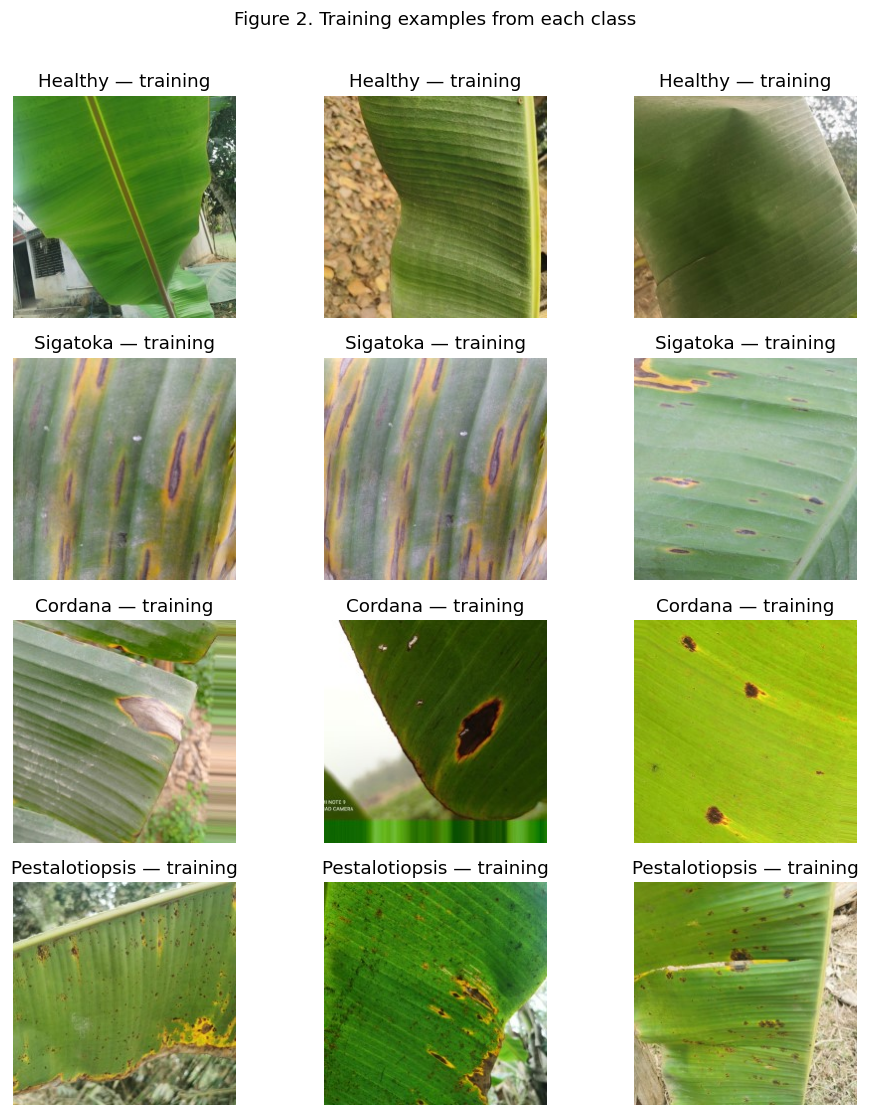

In [7]:
# Show training images only. Test examples remain unopened until evaluation is locked.
fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(9, 10))
for row, name in enumerate(CLASS_NAMES):
    samples = train_df[train_df.class_name == name].sample(n=min(3, sum(train_df.class_name == name)), random_state=SEED)
    for col in range(3):
        ax = axes[row, col]
        if col < len(samples):
            with Image.open(samples.iloc[col].path) as image:
                ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))
            ax.set_title(f"{name} — training")
        ax.axis("off")
fig.suptitle("Figure 2. Training examples from each class", y=1.01)
fig.tight_layout(); fig.savefig(EXPORT_ROOT / "fig02_training_samples.png", bbox_inches="tight"); plt.show()

## 7. Run identity and reproducibility
The run identifier includes the curated data, split and training settings. Existing **completed** experiment models are reused on reruns of the same run. Do not use multiple run folders to search for higher test scores. Pin the saved package versions and retain the saved manifests when reproducing the study.

In [8]:
settings = {"seed": SEED, "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE,
            "scratch_epochs": SCRATCH_EPOCHS, "head_epochs": HEAD_EPOCHS,
            "finetune_epochs": FINETUNE_EPOCHS, "patience": PATIENCE,
            "head_lr": HEAD_LR, "finetune_lr": FINETUNE_LR,
            "finetune_last_layers": FINETUNE_LAST_LAYERS, "dropout": DROPOUT,
            "dhash_distance": NEAR_DUPLICATE_DHASH_DISTANCE,
            "outer_folds": OUTER_FOLDS, "inner_folds": INNER_FOLDS,
            "classes": CLASS_NAMES, "augmentation": "horizontal_flip+rotation_0.06+zoom_0.10+contrast_0.10",
            "selection": "validation_macro_f1_then_accuracy_then_experiment_name",
            "pipeline_version": "1.0"}
content_signature = df[comparison_columns].sort_values("relative_path").to_json(orient="records")
dataset_fingerprint = hashlib.sha256(content_signature.encode()).hexdigest()
run_signature = hashlib.sha256((dataset_fingerprint + json.dumps(settings, sort_keys=True) + tf.__version__).encode()).hexdigest()[:12]
RUN_DIR = EXPORT_ROOT / f"run_{run_signature}"
RUN_DIR.mkdir(exist_ok=True)
for file in EXPORT_ROOT.glob("*.csv"):
    shutil.copy2(file, RUN_DIR / file.name)
for file in EXPORT_ROOT.glob("*.png"):
    shutil.copy2(file, RUN_DIR / file.name)
save_json({"settings": settings, "dataset_fingerprint": dataset_fingerprint,
           "run_signature": run_signature, "source": DATA_SOURCE, "dataset_url": DATASET_URL,
           "created_utc": datetime.now(timezone.utc).isoformat(),
           "student": {"name": STUDENT_NAME, "register_no": REGISTER_NO, "section": SECTION,
                       "github": GITHUB_NOTEBOOK_URL}}, RUN_DIR / "run_config.json")
versions = {"python": platform.python_version(), "tensorflow": tf.__version__, "numpy": np.__version__,
            "pandas": pd.__version__, "platform": platform.platform(),
            "gpu_devices": [str(x) for x in tf.config.list_physical_devices("GPU")]}
save_json(versions, RUN_DIR / "environment.json")
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True)
(RUN_DIR / "requirements_run.txt").write_text(freeze.stdout, encoding="utf-8")
print("Run folder:", RUN_DIR)

Run folder: /content/banana_ps01/outputs/RA2311026050059_PS01/run_930c81166314


## 8. Input pipeline and training-only imbalance handling
Images are decoded by Pillow consistently with the pixel audit (including EXIF orientation), converted to RGB, and resized to 224 × 224. The tensor range remains **0–255**. Scaling is inside each model: scratch CNN uses **0–1**; MobileNetV2 uses **−1 to 1**. Do not divide the data pipeline by 255 a second time.

Augmentation layers are inside the model and are inactive for `predict` / inference. Training class weights are computed only from `train_df`, with no resampling or transformation of validation/test sets. Decoding is deterministic; a small on-disk tf.data cache avoids repeated Python image reads.

In [9]:
weights = compute_class_weight(class_weight="balanced", classes=np.arange(NUM_CLASSES), y=train_df.label.to_numpy())
CLASS_WEIGHTS = {int(i): float(w) for i, w in enumerate(weights)}
weight_table = pd.DataFrame({"class": CLASS_NAMES,
                            "train_images": [int(sum(train_df.label == i)) for i in range(NUM_CLASSES)],
                            "balanced_weight": weights})
weight_table.to_csv(RUN_DIR / "training_class_weights.csv", index=False)
display(weight_table)

CACHE_DIR = WORK_ROOT / "tf_cache" / run_signature
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def decode_pil(path_tensor):
    path = path_tensor.numpy().decode("utf-8")
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        image = image.resize((IMAGE_SIZE[1], IMAGE_SIZE[0]), Image.Resampling.BILINEAR)
        array = np.asarray(image, dtype=np.float32)
    return array

def decode_image(path, label):
    image = tf.py_function(decode_pil, [path], Tout=tf.float32)
    image.set_shape((*IMAGE_SIZE, 3))
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, training=False, cache_name=None):
    dataset = tf.data.Dataset.from_tensor_slices((frame.path.astype(str).to_numpy(), frame.label.to_numpy(np.int32)))
    options = tf.data.Options()
    options.experimental_deterministic = True
    options.threading.private_threadpool_size = 2
    dataset = dataset.with_options(options).map(decode_image, num_parallel_calls=2, deterministic=True)
    if cache_name:
        dataset = dataset.cache(str(CACHE_DIR / cache_name))
    if training:
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(1)

# Test dataset is deliberately not constructed until selection is locked.
val_ds = make_dataset(val_df, cache_name="validation")
images, labels = next(iter(make_dataset(train_df.head(4))))
assert images.shape[1:] == (*IMAGE_SIZE, 3)
assert bool(tf.reduce_all(tf.math.is_finite(images)))
assert float(tf.reduce_min(images)) >= 0 and float(tf.reduce_max(images)) <= 255
print("Batch:", images.shape, "Range:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))

,class,train_images,balanced_weight
0,Healthy,55,2.445455
1,Sigatoka,282,0.476950
2,Cordana,98,1.372449
3,Pestalotiopsis,103,1.305825


Batch: (4, 224, 224, 3) Range: 0.0 255.0


## 9. Architectures and hyperparameters
Both transfer-learning runs start from the same ImageNet weights and seeded classification head. The head trains first with the backbone frozen; the final 30 backbone layers are then considered for fine-tuning at a lower learning rate, **excluding BatchNormalization layers**. The backbone is always called with `training=False`; other trainable convolution weights still receive gradients.

Within each transfer experiment, the better head-only versus fine-tuned checkpoint is retained using validation macro F1 (ties keep head-only). Validation macro F1 also drives early stopping and checkpointing. No test labels are used for model construction, training or selection.

In [10]:
params = pd.DataFrame([
    ["Input", "224 × 224 RGB; source pixels 0–255"],
    ["Split", "Approx. 60/20/20 stratified similarity-group split; saved manifest"],
    ["Optimizer / loss", "Adam / sparse categorical cross-entropy"],
    ["Batch size", BATCH_SIZE],
    ["Initial / fine-tune LR", f"{HEAD_LR} / {FINETUNE_LR}"],
    ["Maximum epochs", f"Scratch {SCRATCH_EPOCHS}; transfer head {HEAD_EPOCHS} + fine-tune {FINETUNE_EPOCHS}"],
    ["Early stopping", f"Validation macro F1; patience {PATIENCE}; restore via best checkpoint"],
    ["Augmentation (train only)", "Horizontal flip; rotation ±0.06 turn; zoom ±10%; contrast ±10%"],
    ["Regularization", f"Global average pooling; dropout {DROPOUT}"],
    ["Imbalance intervention", "Balanced training-only class weights in weighted MobileNet candidate"],
], columns=["Hyperparameter", "Value"])
params.to_csv(RUN_DIR / "hyperparameters.csv", index=False)
display(params)

def augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.06, fill_mode="reflect", seed=SEED + 1),
        layers.RandomZoom(0.10, fill_mode="reflect", seed=SEED + 2),
        layers.RandomContrast(0.10, seed=SEED + 3),
    ], name="train_augmentation")

def build_scratch():
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="rgb_0_255")
    x = augmentation()(inputs)
    x = layers.Rescaling(1 / 255.0, name="scratch_preprocess")(x)
    for i, filters in enumerate([32, 64, 128], start=1):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=f"conv_{i}")(x)
        x = layers.MaxPooling2D(name=f"pool_{i}")(x)
    x = layers.GlobalAveragePooling2D(name="global_pool")(x)
    x = layers.Dropout(DROPOUT, seed=SEED + 4, name="head_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="classifier")(x)
    return keras.Model(inputs, outputs, name="scratch_cnn")

def build_transfer():
    # Download ImageNet weights once. An offline lab must provide/cache these weights.
    backbone = keras.applications.MobileNetV2(include_top=False, weights="imagenet",
                                             input_shape=(*IMAGE_SIZE, 3))
    backbone.trainable = False
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="rgb_0_255")
    x = augmentation()(inputs)
    x = layers.Rescaling(1 / 127.5, offset=-1, name="mobilenet_preprocess")(x)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_pool")(x)
    x = layers.Dropout(DROPOUT, seed=SEED + 4, name="head_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="classifier")(x)
    return keras.Model(inputs, outputs, name="banana_mobilenetv2"), backbone

def compile_model(model, learning_rate):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")])

reset_seeds()
preview = build_scratch()
preview.summary()
del preview

,Hyperparameter,Value
0,Input,224 × 224 RGB; source pixels 0–255
1,Split,Approx. 60/20/20 stratified similarity-group s...
2,Optimizer / loss,Adam / sparse categorical cross-entropy
3,Batch size,32
4,Initial / fine-tune LR,0.001 / 1e-05
5,Maximum epochs,Scratch 20; transfer head 12 + fine-tune 12
6,Early stopping,Validation macro F1; patience 4; restore via b...
7,Augmentation (train only),Horizontal flip; rotation ±0.06 turn; zoom ±10...
8,Regularization,Global average pooling; dropout 0.3
9,Imbalance intervention,Balanced training-only class weights in weight...


Model: "scratch_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_0_255 (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ train_augmentation (Sequential) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scratch_preprocess (Rescaling)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_pool                     │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,764 (366.27 KB)

 Trainable params: 93,764 (366.27 KB)

 Non-trainable params: 0 (0.00 B)

## 10. Training utilities
Each phase computes validation macro F1 after every epoch, before the checkpoint and early-stop callbacks inspect it. We keep all learning-curve values and wall-clock phase times. On rerunning an already completed experiment, its saved model and metadata are loaded rather than silently retraining against a known test set.

In [11]:
class ValidationMacroF1(keras.callbacks.Callback):
    def __init__(self, dataset, y_true):
        super().__init__()
        self.dataset = dataset
        self.y_true = np.asarray(y_true)
    def on_epoch_end(self, epoch, logs=None):
        probabilities = self.model.predict(self.dataset, verbose=0)
        value = f1_score(self.y_true, probabilities.argmax(1), labels=np.arange(NUM_CLASSES),
                         average="macro", zero_division=0)
        if logs is not None:
            logs["val_macro_f1"] = float(value)
        print(f" — val_macro_f1: {value:.4f}")

class EpochTimer(keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.started = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        if logs is not None:
            logs["epoch_seconds"] = time.perf_counter() - self.started

def validation_scores(model):
    probabilities = model.predict(val_ds, verbose=0)
    predictions = probabilities.argmax(1)
    return {"val_macro_f1": float(f1_score(val_df.label, predictions, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0)),
            "val_accuracy": float(accuracy_score(val_df.label, predictions))}

def fit_phase(model, directory, phase, epochs, learning_rate, weighted):
    compile_model(model, learning_rate)
    checkpoint = directory / f"{phase}_best.keras"
    callbacks = [EpochTimer(), ValidationMacroF1(val_ds, val_df.label),
                 keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_macro_f1", mode="max", save_best_only=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_macro_f1", mode="max", factor=0.5, patience=2, min_lr=1e-7),
                 keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max", patience=PATIENCE, min_delta=0.0)]
    started = time.perf_counter()
    history = model.fit(make_dataset(train_df, training=True, cache_name="training"),
                        validation_data=val_ds, epochs=epochs,
                        class_weight=CLASS_WEIGHTS if weighted else None,
                        callbacks=callbacks, verbose=2)
    elapsed = time.perf_counter() - started
    history_frame = pd.DataFrame(history.history)
    history_frame.insert(0, "epoch", np.arange(1, len(history_frame) + 1))
    history_frame["phase"] = phase
    history_frame.to_csv(directory / f"{phase}_history.csv", index=False)
    return keras.models.load_model(checkpoint, compile=False), {"phase": phase, "epochs_run": len(history_frame), "seconds": elapsed}

experiments = [
    {"name": "scratch_cnn", "architecture": "scratch", "weighted": False},
    {"name": "mobilenet_unweighted", "architecture": "mobilenet", "weighted": False},
    {"name": "mobilenet_weighted", "architecture": "mobilenet", "weighted": True},
]

def train_experiment(spec):
    directory = RUN_DIR / spec["name"]
    directory.mkdir(exist_ok=True)
    final_path, metadata_path = directory / "final.keras", directory / "training_metadata.json"
    if final_path.exists() and metadata_path.exists():
        metadata = json.loads(metadata_path.read_text())
        if metadata["model_sha256"] != sha256_file(final_path):
            raise RuntimeError("Completed model file changed; refusing reuse.")
        print("Reusing completed experiment:", spec["name"])
        return metadata
    if (RUN_DIR / "test_evaluation_lock.json").exists():
        raise RuntimeError("Test was already exposed. Do not retrain or add candidates in this run.")
    keras.backend.clear_session()
    reset_seeds()
    phases = []
    if spec["architecture"] == "scratch":
        model = build_scratch()
        model, record = fit_phase(model, directory, "scratch", SCRATCH_EPOCHS, HEAD_LR, spec["weighted"])
        phases.append(record)
        selected_phase = "scratch"
        score = validation_scores(model)
    else:
        model, _ = build_transfer()
        model, record = fit_phase(model, directory, "head", HEAD_EPOCHS, HEAD_LR, spec["weighted"])
        phases.append(record)
        head_score = validation_scores(model)
        backbone = next(layer for layer in model.layers if isinstance(layer, keras.Model) and "mobilenet" in layer.name.lower())
        backbone.trainable = True
        for index, layer in enumerate(backbone.layers):
            layer.trainable = index >= len(backbone.layers) - FINETUNE_LAST_LAYERS and not isinstance(layer, layers.BatchNormalization)
        model, record = fit_phase(model, directory, "finetune", FINETUNE_EPOCHS, FINETUNE_LR, spec["weighted"])
        phases.append(record)
        finetune_score = validation_scores(model)
        if finetune_score["val_macro_f1"] > head_score["val_macro_f1"]:
            score, selected_phase = finetune_score, "finetune"
        else:
            model = keras.models.load_model(directory / "head_best.keras", compile=False)
            score, selected_phase = head_score, "head"
        save_json({"head": head_score, "finetune": finetune_score}, directory / "phase_validation_scores.json")
    model.save(final_path)
    metadata = {**spec, **score, "selected_phase": selected_phase, "phases": phases,
                "training_seconds": sum(p["seconds"] for p in phases),
                "epochs_run": sum(p["epochs_run"] for p in phases),
                "parameter_count": int(model.count_params()), "model_sha256": sha256_file(final_path),
                "model_path": str(final_path)}
    save_json(metadata, metadata_path)
    del model
    return metadata

## 11. Run the three predeclared experiments
This is the main training cell. Internet is needed for the first ImageNet-weight download. Runtime depends on your accelerator and early stopping; no training-time estimate or accuracy is guaranteed. Do not interrupt the current experiment if you want its final checkpoint and metadata to be reusable.

In [12]:
training_records = []
for spec in experiments:
    print("\n" + "=" * 72 + "\nEXPERIMENT: " + spec["name"])
    training_records.append(train_experiment(spec))
validation_table = pd.DataFrame([{k: r[k] for k in ["name", "weighted", "selected_phase", "val_accuracy", "val_macro_f1",
                                                              "epochs_run", "training_seconds", "parameter_count"]}
                                 for r in training_records])
validation_table.to_csv(RUN_DIR / "validation_comparison.csv", index=False)
display(validation_table.round(4))
print("These are VALIDATION results, not test results.")


EXPERIMENT: scratch_cnn
Epoch 1/20


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py:887: UserWarning: Image appears to be a malformed MPO file, it will be interpreted as a base JPEG file
  warnings.warn(


 — val_macro_f1: 0.2342
17/17 - 17s - 973ms/step - accuracy: 0.5074 - loss: 1.1743 - val_accuracy: 0.5611 - val_loss: 1.0103 - epoch_seconds: 16.0199 - val_macro_f1: 0.2342 - learning_rate: 0.0010
Epoch 2/20
 — val_macro_f1: 0.2346
17/17 - 3s - 155ms/step - accuracy: 0.5446 - loss: 1.0667 - val_accuracy: 0.5611 - val_loss: 0.9878 - epoch_seconds: 2.0572 - val_macro_f1: 0.2346 - learning_rate: 0.0010
Epoch 3/20
 — val_macro_f1: 0.2786
17/17 - 4s - 255ms/step - accuracy: 0.5613 - loss: 1.0099 - val_accuracy: 0.5722 - val_loss: 0.9337 - epoch_seconds: 4.0064 - val_macro_f1: 0.2786 - learning_rate: 0.0010
Epoch 4/20
 — val_macro_f1: 0.2786
17/17 - 2s - 99ms/step - accuracy: 0.5762 - loss: 0.9751 - val_accuracy: 0.5722 - val_loss: 0.9479 - epoch_seconds: 1.4515 - val_macro_f1: 0.2786 - learning_rate: 0.0010
Epoch 5/20
 — val_macro_f1: 0.3566
17/17 - 2s - 103ms/step - accuracy: 0.6078 - loss: 0.9603 - val_accuracy: 0.6056 - val_loss: 0.8979 - epoch_seconds: 1.4695 - val_macro_f1: 0.3566 - le

,name,weighted,selected_phase,val_accuracy,val_macro_f1,epochs_run,training_seconds,parameter_count
0,scratch_cnn,False,scratch,0.8167,0.7592,20,58.1692,93764
1,mobilenet_unweighted,False,finetune,0.9722,0.9714,17,63.0273,2263108
2,mobilenet_weighted,True,finetune,0.9722,0.9688,20,68.1085,2263108


These are VALIDATION results, not test results.


## 12. Learning curves and validation ablation
Training metrics are measured with augmentation and possibly class-weighted loss; validation is unaugmented and unweighted. Their losses are not perfectly like-for-like, so do not diagnose overfitting from one gap alone. Inspect trends and macro F1, and check whether validation performance degrades as training accuracy rises.

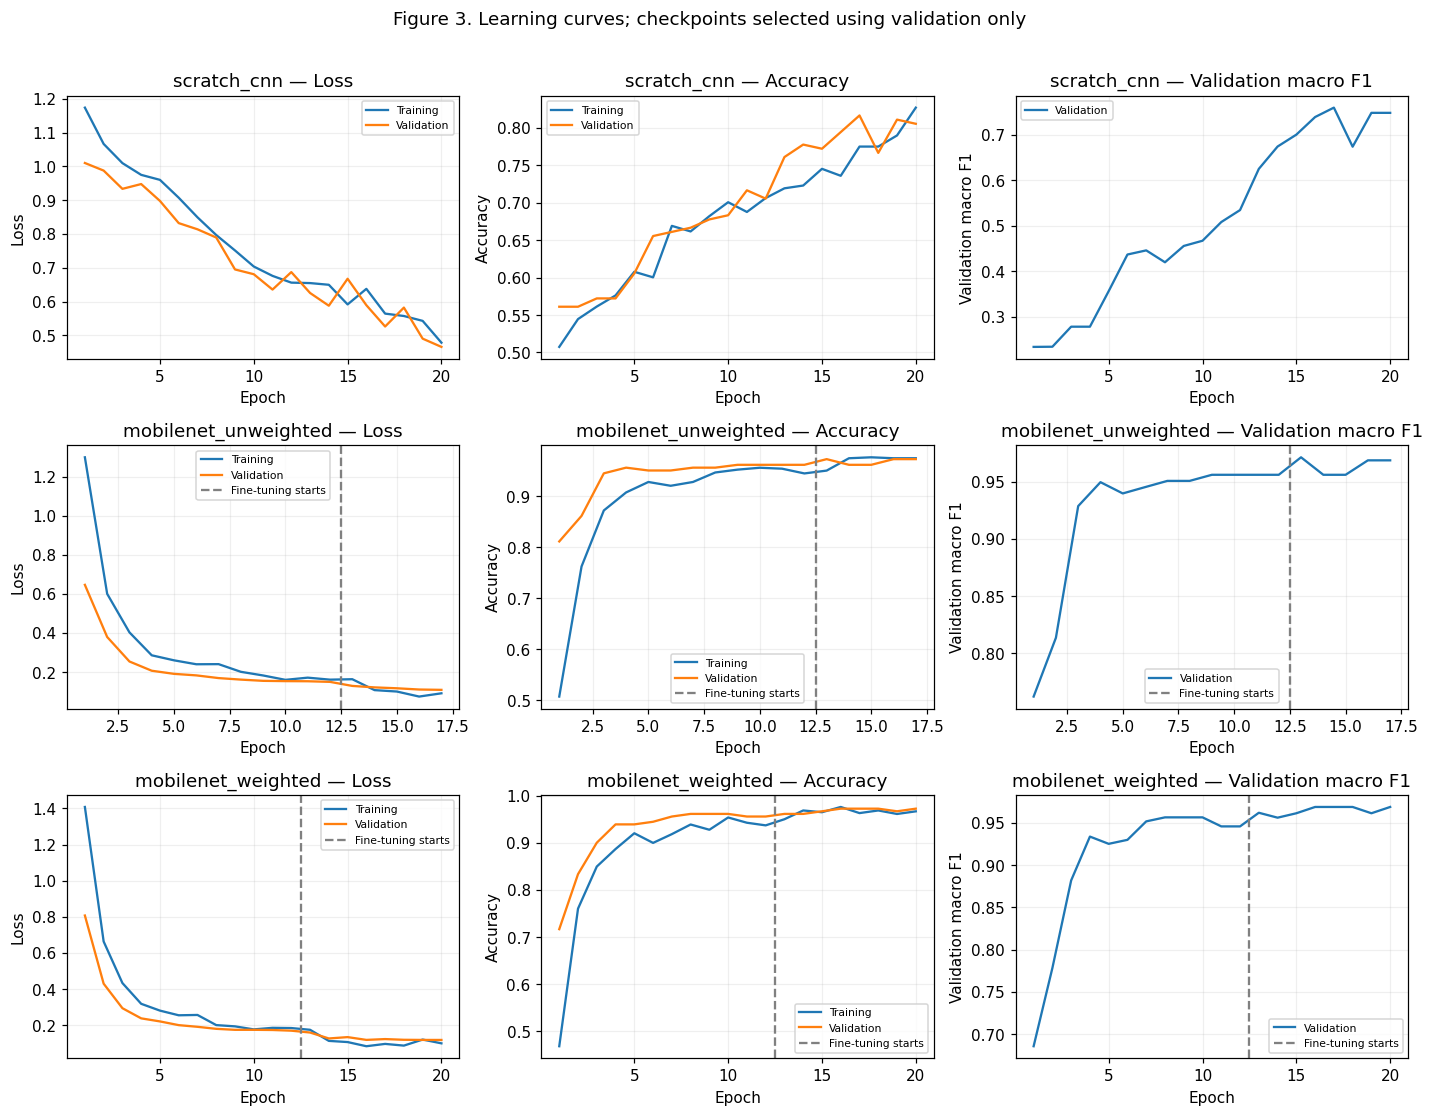

Class-weight ablation: validation macro F1 change = -0.26 percentage points.
This single-seed comparison is evidence for this run only, not a statistically established general improvement.


In [13]:
curve_rows = []
for spec in experiments:
    directory = RUN_DIR / spec["name"]
    ordered = [directory / f"{p}_history.csv" for p in ["scratch", "head", "finetune"]]
    frames = [pd.read_csv(p) for p in ordered if p.exists()]
    combined = pd.concat(frames, ignore_index=True)
    combined["global_epoch"] = np.arange(1, len(combined) + 1)
    combined["model"] = spec["name"]
    curve_rows.append(combined)
curves = pd.concat(curve_rows, ignore_index=True)
curves.to_csv(RUN_DIR / "all_learning_curves.csv", index=False)
fig, axes = plt.subplots(len(experiments), 3, figsize=(13, 10))
for row, spec in enumerate(experiments):
    data = curves[curves.model == spec["name"]]
    for column, (train_key, val_key, title) in enumerate([
        ("loss", "val_loss", "Loss"), ("accuracy", "val_accuracy", "Accuracy"),
        (None, "val_macro_f1", "Validation macro F1")]):
        ax = axes[row, column]
        if train_key: ax.plot(data.global_epoch, data[train_key], label="Training")
        ax.plot(data.global_epoch, data[val_key], label="Validation")
        head_epochs = sum(data.phase == "head")
        if head_epochs and any(data.phase == "finetune"):
            ax.axvline(head_epochs + 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
        ax.set(title=f"{spec['name']} — {title}", xlabel="Epoch", ylabel=title)
        ax.legend(fontsize=7); ax.grid(alpha=0.2)
fig.suptitle("Figure 3. Learning curves; checkpoints selected using validation only", y=1.01)
fig.tight_layout(); fig.savefig(RUN_DIR / "fig03_learning_curves.png", bbox_inches="tight"); plt.show()

unweighted = validation_table.set_index("name").loc["mobilenet_unweighted"]
weighted = validation_table.set_index("name").loc["mobilenet_weighted"]
val_f1_delta = float(weighted.val_macro_f1 - unweighted.val_macro_f1)
print(f"Class-weight ablation: validation macro F1 change = {100 * val_f1_delta:+.2f} percentage points.")
print("This single-seed comparison is evidence for this run only, not a statistically established general improvement.")

## 13. Lock selection BEFORE opening the test set
Selection is **validation macro F1**, then validation accuracy, then experiment name as a deterministic tie-break. All three predeclared candidates are evaluated in a **single final test round** for the results table, but test results never determine the chosen model. Cached probabilities are reused on reruns; changed model files are rejected after the test lock is written. Diagnostic visualisation later does not trigger a new model-selection cycle.

In [14]:
ranking = validation_table.sort_values(["val_macro_f1", "val_accuracy", "name"], ascending=[False, False, True])
SELECTED_NAME = str(ranking.iloc[0]["name"])
locked_models = {r["name"]: {"model_sha256": r["model_sha256"], "val_macro_f1": r["val_macro_f1"]}
                 for r in training_records}
selection = {"selected_name": SELECTED_NAME, "criterion": settings["selection"],
             "dataset_fingerprint": dataset_fingerprint, "models": locked_models}
selection_path = RUN_DIR / "selection_before_test.json"
if selection_path.exists() and json.loads(selection_path.read_text()) != selection:
    raise RuntimeError("Pre-test selection changed. Do not continue with an exposed test set.")
save_json(selection, selection_path)
print("LOCKED using validation only:", SELECTED_NAME)

EVAL_LOCK = RUN_DIR / "test_evaluation_lock.json"
lock_payload = {"selection": selection, "test_count": len(test_df), "status": "started"}
if EVAL_LOCK.exists():
    prior_lock = json.loads(EVAL_LOCK.read_text())
    if prior_lock["selection"] != selection or prior_lock["test_count"] != len(test_df):
        raise RuntimeError("Model/data changed after test exposure; refusing another evaluation round.")
else:
    save_json(lock_payload, EVAL_LOCK)

test_ds = make_dataset(test_df, cache_name="test")
test_rows, prediction_frames, per_class_frames = [], [], []
for record in training_records:
    name = record["name"]
    model_path = RUN_DIR / name / "final.keras"
    assert sha256_file(model_path) == record["model_sha256"]
    predictions_path = RUN_DIR / name / "test_predictions.csv"
    probability_columns = [f"prob_{c}" for c in CLASS_NAMES]
    if predictions_path.exists():
        predictions = pd.read_csv(predictions_path)
        assert predictions.relative_path.tolist() == test_df.relative_path.tolist()
        probabilities = predictions[probability_columns].to_numpy()
    else:
        keras.backend.clear_session()
        model = keras.models.load_model(model_path, compile=False)
        probabilities = model.predict(test_ds, verbose=1)
        predictions = test_df[["relative_path", "class_name", "label", "group_id"]].copy()
        predictions["predicted_label"] = probabilities.argmax(1)
        predictions["predicted_class"] = [CLASS_NAMES[i] for i in probabilities.argmax(1)]
        predictions["confidence"] = probabilities.max(1)
        predictions["correct"] = predictions.label == predictions.predicted_label
        for i, column in enumerate(probability_columns): predictions[column] = probabilities[:, i]
        predictions.to_csv(predictions_path, index=False)
        del model
    assert probabilities.shape == (len(test_df), NUM_CLASSES)
    assert np.isfinite(probabilities).all()
    assert np.allclose(probabilities.sum(1), 1.0, atol=1e-4)
    y_true, y_pred = test_df.label.to_numpy(), probabilities.argmax(1)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(NUM_CLASSES), zero_division=0)
    per_class = pd.DataFrame({"model": name, "class": CLASS_NAMES, "precision": precision,
                              "recall": recall, "f1": f1, "support": support})
    per_class.to_csv(RUN_DIR / name / "test_per_class_metrics.csv", index=False)
    per_class_frames.append(per_class)
    report = classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                   target_names=CLASS_NAMES, zero_division=0, digits=4)
    (RUN_DIR / name / "test_classification_report.txt").write_text(report, encoding="utf-8")
    matrix = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RUN_DIR / name / "test_confusion_matrix.csv")
    test_rows.append({"model": name, "selected_before_test": name == SELECTED_NAME, "split": "test",
                      "test_n": len(y_true), "accuracy": float(accuracy_score(y_true, y_pred)),
                      "macro_f1": float(f1_score(y_true, y_pred, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0)),
                      "training_seconds": record["training_seconds"], "epochs_run": record["epochs_run"],
                      "parameters": record["parameter_count"]})
    prediction_frames.append(predictions.assign(model=name))

test_results = pd.DataFrame(test_rows)
all_predictions = pd.concat(prediction_frames, ignore_index=True)
all_per_class = pd.concat(per_class_frames, ignore_index=True)
test_results.to_csv(RUN_DIR / "test_results.csv", index=False)
all_predictions.to_csv(RUN_DIR / "all_test_predictions.csv", index=False)
all_per_class.to_csv(RUN_DIR / "all_test_per_class_metrics.csv", index=False)
save_json({**lock_payload, "status": "complete"}, EVAL_LOCK)

report_table = test_results[["model", "selected_before_test", "test_n", "accuracy", "macro_f1", "training_seconds"]].copy()
report_table["accuracy"] *= 100
report_table["macro_f1"] *= 100
report_table.rename(columns={"accuracy": "Test accuracy (%)", "macro_f1": "Test macro F1 (%)",
                             "training_seconds": "Training time (s)"}, inplace=True)
report_table.to_csv(RUN_DIR / "report_results_table.csv", index=False, float_format="%.2f")
display(report_table.round(2))
print("Selected model remains", SELECTED_NAME, "regardless of which row has the highest test score.")

LOCKED using validation only: mobilenet_unweighted
4/6 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py:887: UserWarning: Image appears to be a malformed MPO file, it will be interpreted as a base JPEG file
  warnings.warn(


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 306ms/step


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 312ms/step


,model,selected_before_test,test_n,Test accuracy (%),Test macro F1 (%),Training time (s)
0,scratch_cnn,False,179,78.77,68.64,58.17
1,mobilenet_unweighted,True,179,95.53,94.73,63.03
2,mobilenet_weighted,False,179,96.09,95.61,68.11


Selected model remains mobilenet_unweighted regardless of which row has the highest test score.


## 14. Per-class results and confusion matrix
Report the selected model's per-class precision, recall and F1 rather than accuracy alone. Matrix rows are true labels and columns are predicted labels. The normalised view sums to 1 within each true class; use it to compare classes with different support.

,model,class,precision,recall,f1,support
4,mobilenet_unweighted,Healthy,0.9412,0.8889,0.9143,18
5,mobilenet_unweighted,Sigatoka,0.9485,0.9787,0.9634,94
6,mobilenet_unweighted,Cordana,1.0000,0.9688,0.9841,32
7,mobilenet_unweighted,Pestalotiopsis,0.9412,0.9143,0.9275,35


                precision    recall  f1-score   support

       Healthy     0.9412    0.8889    0.9143        18
      Sigatoka     0.9485    0.9787    0.9634        94
       Cordana     1.0000    0.9688    0.9841        32
Pestalotiopsis     0.9412    0.9143    0.9275        35

      accuracy                         0.9553       179
     macro avg     0.9577    0.9377    0.9473       179
  weighted avg     0.9555    0.9553    0.9551       179



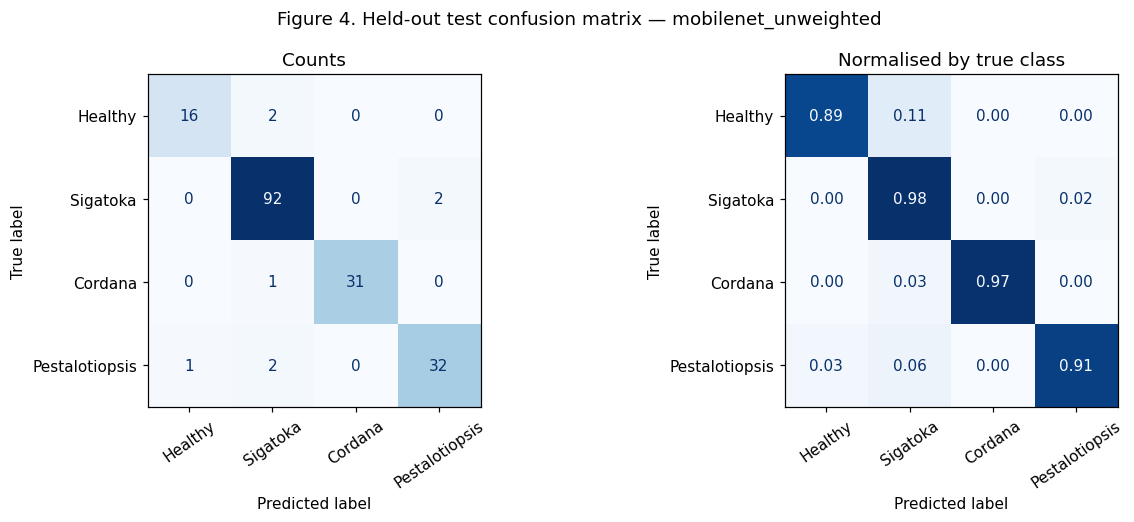

Largest directed confusion: Healthy → Sigatoka (2 test images).


In [15]:
selected_predictions = all_predictions[all_predictions.model == SELECTED_NAME].reset_index(drop=True)
selected_per_class = all_per_class[all_per_class.model == SELECTED_NAME].copy()
display(selected_per_class.round(4))
print((RUN_DIR / SELECTED_NAME / "test_classification_report.txt").read_text())
y_true = selected_predictions.label.to_numpy()
y_pred = selected_predictions.predicted_label.to_numpy()
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, normalise, title in zip(axes, [None, "true"], ["Counts", "Normalised by true class"]):
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=np.arange(NUM_CLASSES),
        display_labels=CLASS_NAMES, normalize=normalise, cmap="Blues", ax=ax,
        colorbar=False, values_format="d" if normalise is None else ".2f", xticks_rotation=35)
    ax.set_title(title)
fig.suptitle(f"Figure 4. Held-out test confusion matrix — {SELECTED_NAME}")
fig.tight_layout(); fig.savefig(RUN_DIR / "fig04_test_confusion_matrix.png"); plt.show()
off_diagonal = cm.copy(); np.fill_diagonal(off_diagonal, 0)
if off_diagonal.max() > 0:
    true_index, pred_index = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    confusion_sentence = f"Largest directed confusion: {CLASS_NAMES[true_index]} → {CLASS_NAMES[pred_index]} ({off_diagonal[true_index, pred_index]} test images)."
else:
    confusion_sentence = "No misclassifications occurred on this held-out test set; this does not establish field reliability."
print(confusion_sentence)

## 15. At least four real misclassifications
Show the **four most confident actual errors**, or all errors if fewer than four exist. Never change the split, deliberately weaken a model, or fabricate mistakes to obtain four examples. If fewer than four are available, disclose that and ask your evaluator how to satisfy the example requirement.

The following cell reports measurable brightness and a simple edge-variance sharpness proxy. Low/high flags use thresholds computed **from training images only**. They suggest inspection questions, not verified explanations or a scientific blur diagnosis. For each displayed error, write a reason supported by the actual leaf image and, if helpful, Grad-CAM; do not present the automatic hypotheses as established causes.

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py:887: UserWarning: Image appears to be a malformed MPO file, it will be interpreted as a base JPEG file
  warnings.warn(


Actual selected-model test errors: 8


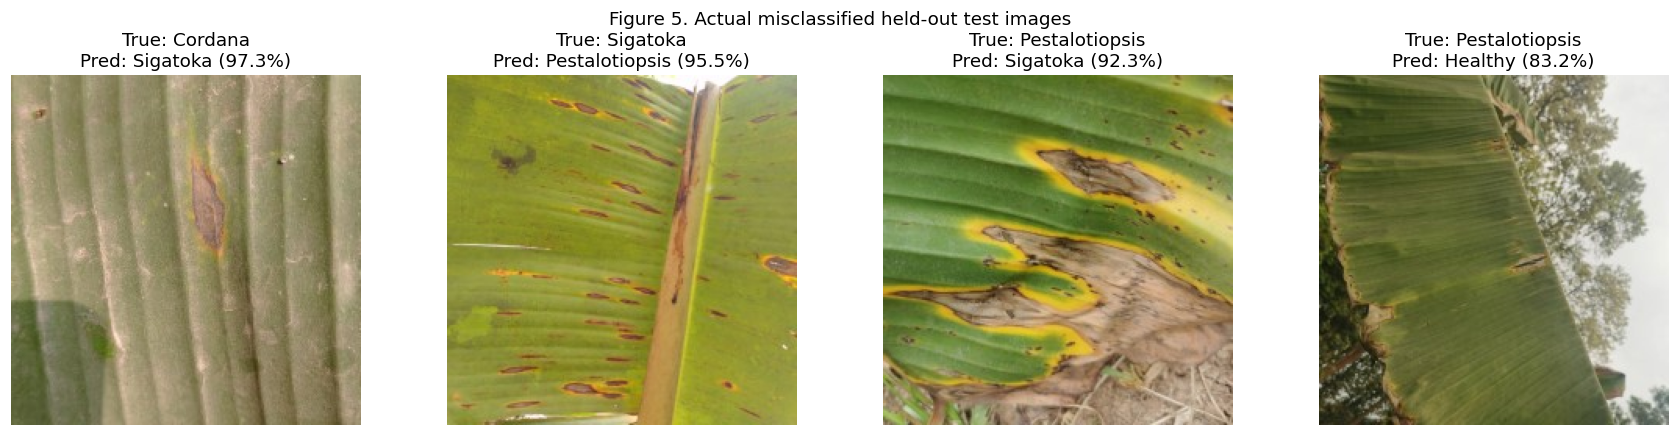

,relative_path,class_name,predicted_class,confidence,inspection_hypothesis_not_verified,student_verified_reason
0,Cordana/140.jpeg,Cordana,Sigatoka,0.972855,No extreme brightness/sharpness flag: inspect ...,
1,Sigatoka/288.jpeg,Sigatoka,Pestalotiopsis,0.954724,No extreme brightness/sharpness flag: inspect ...,
2,Pestalotiopsis/64.jpeg,Pestalotiopsis,Sigatoka,0.922729,No extreme brightness/sharpness flag: inspect ...,
3,Pestalotiopsis/75.jpeg,Pestalotiopsis,Healthy,0.831677,No extreme brightness/sharpness flag: inspect ...,


In [16]:
def visual_stats(path):
    with Image.open(path) as image:
        gray = np.asarray(ImageOps.exif_transpose(image).convert("L").resize((224, 224)), dtype=np.float32)
    laplacian = (-4 * gray[1:-1, 1:-1] + gray[:-2, 1:-1] + gray[2:, 1:-1]
                 + gray[1:-1, :-2] + gray[1:-1, 2:])
    return {"mean_brightness": float(gray.mean()), "edge_variance": float(laplacian.var())}

train_quality = pd.DataFrame([visual_stats(p) for p in train_df.path])
train_quality.to_csv(RUN_DIR / "training_quality_reference.csv", index=False)
brightness_low, brightness_high = np.percentile(train_quality.mean_brightness, [10, 90])
sharpness_low = float(np.percentile(train_quality.edge_variance, 10))
errors = selected_predictions[selected_predictions.label != selected_predictions.predicted_label].copy()
errors = errors.sort_values("confidence", ascending=False).reset_index(drop=True)
path_lookup = dict(zip(test_df.relative_path, test_df.path))
error_details = []
for _, row in errors.iterrows():
    stats = visual_stats(path_lookup[row.relative_path])
    cues = []
    if stats["edge_variance"] < sharpness_low:
        cues.append("Low edge variance relative to training P10: inspect blur or a feature-poor leaf region.")
    if stats["mean_brightness"] < brightness_low:
        cues.append("Brightness below training P10: inspect shadow/underexposure obscuring lesions.")
    if stats["mean_brightness"] > brightness_high:
        cues.append("Brightness above training P90: inspect glare or overexposure.")
    if not cues:
        cues.append("No extreme brightness/sharpness flag: inspect lesion ambiguity, crop coverage, and background attention.")
    error_details.append({**row.to_dict(), **stats, "inspection_hypothesis_not_verified": " ".join(cues),
                          "student_verified_reason": ""})
error_table = pd.DataFrame(error_details)
error_table.to_csv(RUN_DIR / "misclassification_analysis.csv", index=False)
print("Actual selected-model test errors:", len(errors))
if len(errors) < 4:
    print("Fewer than four errors: showing all available errors honestly. Do not fabricate or force additional errors.")
shown_errors = errors.head(4)
if len(shown_errors):
    fig, axes = plt.subplots(1, len(shown_errors), figsize=(4 * len(shown_errors), 4), squeeze=False)
    for i, (_, row) in enumerate(shown_errors.iterrows()):
        with Image.open(path_lookup[row.relative_path]) as image:
            axes[0, i].imshow(ImageOps.exif_transpose(image).convert("RGB"))
        axes[0, i].set_title(f"True: {row.class_name}\nPred: {row.predicted_class} ({row.confidence:.1%})")
        axes[0, i].axis("off")
    fig.suptitle("Figure 5. Actual misclassified held-out test images")
    fig.tight_layout(); fig.savefig(RUN_DIR / "fig05_misclassified_test_images.png"); plt.show()
    display(error_table.head(4)[["relative_path", "class_name", "predicted_class", "confidence",
                                  "inspection_hypothesis_not_verified", "student_verified_reason"]])
else:
    print("No errors to display. Report this, and discuss test-set size and external-validity limitations.")

## 16. Grad-CAM diagnostic
Grad-CAM is an **explanation diagnostic**, not proof that the model understands a disease. It highlights regions associated with the selected class score. Look for lesion/leaf attention versus soil, hands or background; even a plausible map does not prove causality or safety.

This cell uses the selected model only. MobileNetV2's final convolutional feature tensor is exposed through a separate backbone view so nested-model gradients remain connected. For the scratch model, `conv_3` is used. Attribution uses the pre-softmax class score. No classification threshold or hyperparameter is changed after viewing these diagnostics.

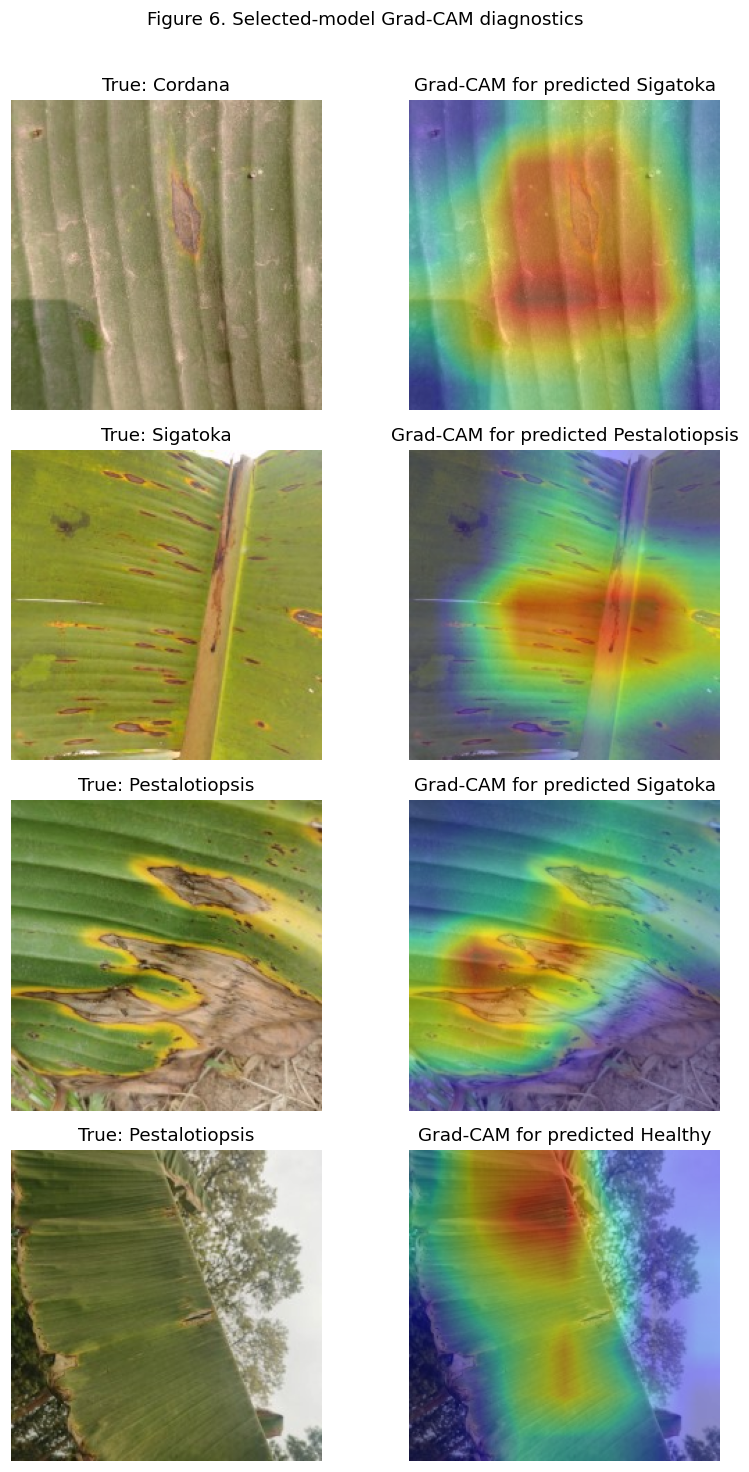

In [17]:
keras.backend.clear_session()
selected_model = keras.models.load_model(RUN_DIR / SELECTED_NAME / "final.keras", compile=False)

def load_rgb_batch(path):
    with Image.open(path) as image:
        rgb = ImageOps.exif_transpose(image).convert("RGB").resize((IMAGE_SIZE[1], IMAGE_SIZE[0]), Image.Resampling.BILINEAR)
        array = np.asarray(rgb, dtype=np.float32)
    return array, tf.convert_to_tensor(array[None, ...])

def gradcam(model, input_batch, class_id):
    classifier = model.get_layer("classifier")
    if SELECTED_NAME.startswith("mobilenet"):
        backbone = next(layer for layer in model.layers if isinstance(layer, keras.Model) and "mobilenet" in layer.name.lower())
        with tf.GradientTape() as tape:
            tape.watch(input_batch)
            x = model.get_layer("mobilenet_preprocess")(input_batch)
            features = backbone(x, training=False)
            tape.watch(features)
            pooled = model.get_layer("global_pool")(features)
            pooled = model.get_layer("head_dropout")(pooled, training=False)
            logits = tf.matmul(pooled, classifier.kernel) + classifier.bias
            score = logits[:, class_id]
        gradients = tape.gradient(score, features)
    else:
        view = keras.Model(model.inputs, [model.get_layer("conv_3").output, model.get_layer("head_dropout").output])
        with tf.GradientTape() as tape:
            tape.watch(input_batch)
            features, pooled = view(input_batch, training=False)
            logits = tf.matmul(pooled, classifier.kernel) + classifier.bias
            score = logits[:, class_id]
        gradients = tape.gradient(score, features)
    if gradients is None:
        raise RuntimeError("Grad-CAM gradients disconnected; do not display an invalid heatmap.")
    weights = tf.reduce_mean(gradients, axis=(1, 2))
    heatmap = tf.nn.relu(tf.reduce_sum(features * weights[:, None, None, :], axis=-1))[0]
    heatmap = tf.math.divide_no_nan(heatmap, tf.reduce_max(heatmap))
    heatmap = tf.image.resize(heatmap[..., None], IMAGE_SIZE).numpy()[..., 0]
    return heatmap

cam_examples = shown_errors if len(shown_errors) else selected_predictions.head(4)
cam_data = []
if len(cam_examples):
    fig, axes = plt.subplots(len(cam_examples), 2, figsize=(8, 3.3 * len(cam_examples)), squeeze=False)
    for i, (_, row) in enumerate(cam_examples.iterrows()):
        array, batch = load_rgb_batch(path_lookup[row.relative_path])
        heatmap = gradcam(selected_model, batch, int(row.predicted_label))
        cam_data.append({"relative_path": row.relative_path, "maximum_normalized_heatmap": float(heatmap.max()),
                         "target_class": row.predicted_class})
        axes[i, 0].imshow(array.astype(np.uint8)); axes[i, 0].set_title(f"True: {row.class_name}")
        axes[i, 1].imshow(array.astype(np.uint8))
        axes[i, 1].imshow(heatmap, cmap="jet", alpha=0.40, vmin=0, vmax=1)
        axes[i, 1].set_title(f"Grad-CAM for predicted {row.predicted_class}")
        for ax in axes[i]: ax.axis("off")
    fig.suptitle("Figure 6. Selected-model Grad-CAM diagnostics", y=1.01)
    fig.tight_layout(); fig.savefig(RUN_DIR / "fig06_gradcam.png", bbox_inches="tight"); plt.show()
    pd.DataFrame(cam_data).to_csv(RUN_DIR / "gradcam_examples.csv", index=False)

## 17. Complete your evidence-based discussion
Run these cells after reviewing the error figures. Fill `ERROR_EXPLANATIONS` using the **exact relative paths** displayed above; fill at least four when four errors exist. Each value should name an observed cue and state uncertainty, e.g. “The lesion occupies only a small corner; the heatmap emphasizes the background, suggesting a possible shortcut.” Use that wording only if your own image supports it.

Write `LEARNING_CURVE_DISCUSSION` from the actual saved curves. The supplied report draft deliberately does not invent observed overfitting, specific lesion causes, or a deployment claim.

In [18]:
# Fill these AFTER inspecting your own outputs, not from a guessed example.
ERROR_EXPLANATIONS = {
    # "healthy/12.jpeg": "Your own image-supported explanation, with uncertainty.",
}
LEARNING_CURVE_DISCUSSION = "TODO: describe actual training/validation trends and cite Fig. 3."
GRADCAM_DISCUSSION = "TODO: describe attention patterns actually visible in Fig. 6; do not claim causal proof."

if not error_table.empty:
    error_table["student_verified_reason"] = error_table.relative_path.map(ERROR_EXPLANATIONS).fillna("")
    error_table.to_csv(RUN_DIR / "misclassification_analysis.csv", index=False)
required_explanations = min(4, len(errors))
completed_explanations = sum(bool(ERROR_EXPLANATIONS.get(path, "").strip()) for path in shown_errors.relative_path)
print(f"Error explanations completed for required examples: {completed_explanations}/{required_explanations}")
if completed_explanations < required_explanations:
    print("ACTION: inspect the images and fill the missing error explanations before submission.")

Error explanations completed for required examples: 0/4
ACTION: inspect the images and fill the missing error explanations before submission.


## 18. Report-ready text and exact results
This creates a **draft**, not an automatically compliant two-page PDF. It contains the required seven sections, real result tables, split sizes, citations, ethics and AI disclosure. Replace all TODOs, shorten to the required length, and use the formatting rules below. Validation ablation evidence stays labelled as validation; final performance claims use the test set.

**Report formatting from your brief:** A4, maximum 2 pages including figures/tables, no separate cover, Times New Roman 11 pt body / 12 pt bold headings, single spacing, 2 cm margins. Caption/number every table and figure; report test numbers to two decimals; include the dataset/paper citation and GitHub link. Export as **RegisterNo_PS01_Report.pdf**. Do not submit this Markdown draft in place of the required PDF.

In [19]:
def markdown_table(frame, digits=2):
    table = frame.copy()
    def fmt(value):
        if isinstance(value, (float, np.floating)): return f"{value:.{digits}f}"
        return str(value).replace("|", "/").replace("\n", " ")
    header = "| " + " | ".join(map(str, table.columns)) + " |"
    separator = "| " + " | ".join(["---"] * len(table.columns)) + " |"
    lines = ["| " + " | ".join(fmt(v) for v in row) + " |" for row in table.itertuples(index=False, name=None)]
    return "\n".join([header, separator] + lines)

selected_result = test_results.set_index("model").loc[SELECTED_NAME]
per_class_display = selected_per_class[["class", "precision", "recall", "f1", "support"]].copy()
for column in ["precision", "recall", "f1"]: per_class_display[column] *= 100
per_class_display.rename(columns={"precision": "Precision (%)", "recall": "Recall (%)", "f1": "F1 (%)"}, inplace=True)
heldout_majority_accuracy = float(np.mean(test_df.label.to_numpy() == int(train_df.label.mode().iloc[0])))

error_notes = []
for _, row in shown_errors.iterrows():
    reason = ERROR_EXPLANATIONS.get(row.relative_path, "TODO: inspect this specific image and explain a likely reason without claiming certainty.")
    error_notes.append(f"- {row.relative_path}: true {row.class_name}, predicted {row.predicted_class}; {reason}")

report_lines = [
    "# PS-01 — Banana Leaf Spot Disease Classification",
    f"{STUDENT_NAME} | {REGISTER_NO} | {SECTION} | PS-01 | {datetime.now().date()} | {GITHUB_NOTEBOOK_URL}",
    "## 1. Problem and Objective",
    "Classify banana-leaf photos into Healthy, Sigatoka, Cordana, or Pestalotiopsis as an educational screening prototype. "
    "Judge model selection by validation macro F1 so minority-class performance matters; measure final performance only on the held-out test set.",
    "## 2. Dataset and Preprocessing",
    f"BananaLSD v1 OriginalSet only. Loaded {len(raw_df)} readable original images; excluded {len(conflicts)} images with exact conflicting labels, "
    f"removed {len(repeats)} repeated same-label images, and logged {len(corrupt_rows)} unreadable files. Used {len(df)} images: "
    f"{len(train_df)} train, {len(val_df)} validation, {len(test_df)} test. The split is stratified and similarity-group-aware (seed {SEED}). "
    "RGB images are resized to 224 × 224. Scratch inputs use 0–1 scaling and MobileNetV2 uses −1 to 1. Training-only online augmentation "
    "uses horizontal flips, mild rotations, zoom and contrast. Balanced class weights are calculated from the training split only.",
    "## 3. Methodology",
    "Compared a compact CNN, ImageNet MobileNetV2 without class weights, and otherwise matched MobileNetV2 with class weights. "
    "Transfer models train a frozen-backbone head, then optionally fine-tune the final layers at lower learning rate with BatchNormalization "
    "frozen. Retain head or fine-tuned checkpoints using validation macro F1. Adam, sparse categorical cross-entropy, early stopping and "
    f"dropout {DROPOUT} are used. Model choice was locked before the single final test-evaluation round.",
    "Table 1. Hyperparameters.", markdown_table(params),
    "## 4. Results",
    f"Selected before test: {SELECTED_NAME}. Test accuracy {100 * selected_result.accuracy:.2f}%; "
    f"test macro F1 {100 * selected_result.macro_f1:.2f}%; held-out test size {len(test_df)}. "
    f"A training-majority-label reference obtains {100 * heldout_majority_accuracy:.2f}% accuracy on this same test set.",
    "Table 2. Single-round held-out TEST results; selected_before_test identifies the model chosen without test labels.",
    markdown_table(report_table),
    "Table 3. Selected-model per-class TEST performance.", markdown_table(per_class_display),
    "Figures: use a readable selected-model learning-curve panel and Fig. 4 confusion matrix; keep the other diagnostics in the notebook.",
    "## 5. Analysis and Discussion",
    confusion_sentence,
    f"The predeclared class-weight intervention changes VALIDATION macro F1 by {100 * val_f1_delta:+.2f} percentage points. "
    "This comparison isolates class weights under a matched protocol, not a multi-seed significance claim.",
    LEARNING_CURVE_DISCUSSION, GRADCAM_DISCUSSION,
    f"There are {len(errors)} actual selected-model test errors; {len(shown_errors)} are displayed in the notebook.",
    *error_notes,
    "## 6. Real-world Relevance, Limitations and Ethics",
    "Possible use is farmer-facing triage, not an autonomous diagnosis or pesticide recommendation. The dataset is small and geographically "
    "limited; no external farm/camera evaluation, clinical-style sensitivity validation, latency study or prospective safety test was performed. "
    "Near-duplicate grouping cannot prove plant/session independence because those IDs are unavailable. "
    "Similar lesions, mixed infections, new diseases and unknown crops are outside the closed four-class task. Softmax confidence is not "
    "calibrated diagnostic certainty. Misclassification could delay treatment or prompt unnecessary chemical use; expert review is required. "
    "For future phone collection obtain consent, remove location/identity metadata, and measure performance across farms, devices and lighting.",
    "## 7. Conclusion and Future Work",
    f"The validation-selected {SELECTED_NAME} achieves {100 * selected_result.accuracy:.2f}% accuracy and "
    f"{100 * selected_result.macro_f1:.2f}% macro F1 on {len(test_df)} held-out test images. Next, test prospectively on "
    "a genuinely external farm/device dataset with plant-level IDs and uncertainty handling before considering deployment.",
    "Dataset/paper citation: Arman et al. (2023), BananaLSD v1, Mendeley Data, doi:10.17632/9tb7k297ff.1; "
    "Arman et al., Data in Brief 50, 109608, doi:10.1016/j.dib.2023.109608. Dataset licence: CC BY 4.0.",
    "AI assistance disclosure (edit to match actual use): An AI assistant generated the starting notebook structure and code. "
    "I am responsible for reviewing, running, explaining and verifying every submitted cell and result. "
    "TODO: state any further AI use and cite any external code/tutorial adapted. Architectural guidance: "
    "https://keras.io/guides/transfer_learning/ ; https://keras.io/api/applications/mobilenet/mobilenet_models/ .",
]
report_text = "\n\n".join(report_lines)
report_path = RUN_DIR / f"{safe_register}_{PS_NO}_Report_Draft.md"
report_path.write_text(report_text, encoding="utf-8")
display(Markdown(report_text))
print("Draft saved. It MUST be edited and formatted into the required maximum-two-page PDF.")

# PS-01 — Banana Leaf Spot Disease Classification

Kamisetty Koushik | RA2311026050059 | AIML-B | PS-01 | 2026-10-23 | https://github.com/koushik5636N/DL-CBL

## 1. Problem and Objective

Classify banana-leaf photos into Healthy, Sigatoka, Cordana, or Pestalotiopsis as an educational screening prototype. Judge model selection by validation macro F1 so minority-class performance matters; measure final performance only on the held-out test set.

## 2. Dataset and Preprocessing

BananaLSD v1 OriginalSet only. Loaded 937 readable original images; excluded 2 images with exact conflicting labels, removed 38 repeated same-label images, and logged 0 unreadable files. Used 897 images: 538 train, 180 validation, 179 test. The split is stratified and similarity-group-aware (seed 42). RGB images are resized to 224 × 224. Scratch inputs use 0–1 scaling and MobileNetV2 uses −1 to 1. Training-only online augmentation uses horizontal flips, mild rotations, zoom and contrast. Balanced class weights are calculated from the training split only.

## 3. Methodology

Compared a compact CNN, ImageNet MobileNetV2 without class weights, and otherwise matched MobileNetV2 with class weights. Transfer models train a frozen-backbone head, then optionally fine-tune the final layers at lower learning rate with BatchNormalization frozen. Retain head or fine-tuned checkpoints using validation macro F1. Adam, sparse categorical cross-entropy, early stopping and dropout 0.3 are used. Model choice was locked before the single final test-evaluation round.

Table 1. Hyperparameters.

| Hyperparameter | Value |
| --- | --- |
| Input | 224 × 224 RGB; source pixels 0–255 |
| Split | Approx. 60/20/20 stratified similarity-group split; saved manifest |
| Optimizer / loss | Adam / sparse categorical cross-entropy |
| Batch size | 32 |
| Initial / fine-tune LR | 0.001 / 1e-05 |
| Maximum epochs | Scratch 20; transfer head 12 + fine-tune 12 |
| Early stopping | Validation macro F1; patience 4; restore via best checkpoint |
| Augmentation (train only) | Horizontal flip; rotation ±0.06 turn; zoom ±10%; contrast ±10% |
| Regularization | Global average pooling; dropout 0.3 |
| Imbalance intervention | Balanced training-only class weights in weighted MobileNet candidate |

## 4. Results

Selected before test: mobilenet_unweighted. Test accuracy 95.53%; test macro F1 94.73%; held-out test size 179. A training-majority-label reference obtains 52.51% accuracy on this same test set.

Table 2. Single-round held-out TEST results; selected_before_test identifies the model chosen without test labels.

| model | selected_before_test | test_n | Test accuracy (%) | Test macro F1 (%) | Training time (s) |
| --- | --- | --- | --- | --- | --- |
| scratch_cnn | False | 179 | 78.77 | 68.64 | 58.17 |
| mobilenet_unweighted | True | 179 | 95.53 | 94.73 | 63.03 |
| mobilenet_weighted | False | 179 | 96.09 | 95.61 | 68.11 |

Table 3. Selected-model per-class TEST performance.

| class | Precision (%) | Recall (%) | F1 (%) | support |
| --- | --- | --- | --- | --- |
| Healthy | 94.12 | 88.89 | 91.43 | 18 |
| Sigatoka | 94.85 | 97.87 | 96.34 | 94 |
| Cordana | 100.00 | 96.88 | 98.41 | 32 |
| Pestalotiopsis | 94.12 | 91.43 | 92.75 | 35 |

Figures: use a readable selected-model learning-curve panel and Fig. 4 confusion matrix; keep the other diagnostics in the notebook.

## 5. Analysis and Discussion

Largest directed confusion: Healthy → Sigatoka (2 test images).

The predeclared class-weight intervention changes VALIDATION macro F1 by -0.26 percentage points. This comparison isolates class weights under a matched protocol, not a multi-seed significance claim.

TODO: describe actual training/validation trends and cite Fig. 3.

TODO: describe attention patterns actually visible in Fig. 6; do not claim causal proof.

There are 8 actual selected-model test errors; 4 are displayed in the notebook.

- Cordana/140.jpeg: true Cordana, predicted Sigatoka; TODO: inspect this specific image and explain a likely reason without claiming certainty.

- Sigatoka/288.jpeg: true Sigatoka, predicted Pestalotiopsis; TODO: inspect this specific image and explain a likely reason without claiming certainty.

- Pestalotiopsis/64.jpeg: true Pestalotiopsis, predicted Sigatoka; TODO: inspect this specific image and explain a likely reason without claiming certainty.

- Pestalotiopsis/75.jpeg: true Pestalotiopsis, predicted Healthy; TODO: inspect this specific image and explain a likely reason without claiming certainty.

## 6. Real-world Relevance, Limitations and Ethics

Possible use is farmer-facing triage, not an autonomous diagnosis or pesticide recommendation. The dataset is small and geographically limited; no external farm/camera evaluation, clinical-style sensitivity validation, latency study or prospective safety test was performed. Near-duplicate grouping cannot prove plant/session independence because those IDs are unavailable. Similar lesions, mixed infections, new diseases and unknown crops are outside the closed four-class task. Softmax confidence is not calibrated diagnostic certainty. Misclassification could delay treatment or prompt unnecessary chemical use; expert review is required. For future phone collection obtain consent, remove location/identity metadata, and measure performance across farms, devices and lighting.

## 7. Conclusion and Future Work

The validation-selected mobilenet_unweighted achieves 95.53% accuracy and 94.73% macro F1 on 179 held-out test images. Next, test prospectively on a genuinely external farm/device dataset with plant-level IDs and uncertainty handling before considering deployment.

Dataset/paper citation: Arman et al. (2023), BananaLSD v1, Mendeley Data, doi:10.17632/9tb7k297ff.1; Arman et al., Data in Brief 50, 109608, doi:10.1016/j.dib.2023.109608. Dataset licence: CC BY 4.0.

AI assistance disclosure (edit to match actual use): An AI assistant generated the starting notebook structure and code. I am responsible for reviewing, running, explaining and verifying every submitted cell and result. TODO: state any further AI use and cite any external code/tutorial adapted. Architectural guidance: https://keras.io/guides/transfer_learning/ ; https://keras.io/api/applications/mobilenet/mobilenet_models/ .

Draft saved. It MUST be edited and formatted into the required maximum-two-page PDF.


## 19. Optional single-image inference
Use only for a genuine new image after the evaluation is complete. An output is one of the four known classes; the model cannot certify an unfamiliar disease, banana identity, or a mixed infection. No treatment advice is produced. Upload a photo manually, set its path, then run this cell. Do not feed the dataset AugmentedSet into a new evaluation.

In [20]:
NEW_IMAGE_PATH = ""  # e.g. "/content/my_banana_leaf.jpg"
if NEW_IMAGE_PATH:
    array, batch = load_rgb_batch(NEW_IMAGE_PATH)
    probabilities = selected_model.predict(batch, verbose=0)[0]
    table = pd.DataFrame({"class": CLASS_NAMES, "softmax_score": probabilities}).sort_values("softmax_score", ascending=False)
    display(table)
    plt.figure(figsize=(4, 4)); plt.imshow(array.astype(np.uint8)); plt.axis("off")
    plt.title(f"Predicted: {table.iloc[0]['class']} — not a verified diagnosis"); plt.show()
else:
    print("Optional inference skipped. Set NEW_IMAGE_PATH to a new photo to try it.")

Optional inference skipped. Set NEW_IMAGE_PATH to a new photo to try it.


## 20. Submission checklist and export
- Replace name/register/section/GitHub placeholders and use your real registration number in filenames.
- Save this notebook **with all outputs**, e.g. `RegisterNo_PS01.ipynb`, and push it to your repository.
- Retain split and audit manifests, resolved versions, run config, final models, predictions, metrics and learning curves. The full zip includes intermediate checkpoints, so it can be large.
- Review at least four error explanations when four errors exist. If fewer exist, disclose the count.
- Write the maximum-two-page report in the prescribed PDF layout, label every figure/table, state the actual curated dataset size and test split, cite sources and disclose AI assistance.
- Be able to explain class weighting, augmentation leakage, duplicate handling, macro F1, validation/test separation, frozen BatchNormalization and limitations during the viva.

The Colab zip download below contains run outputs, **not a saved copy of this live notebook**. Use **File → Download → Download .ipynb** or save to Drive separately to retain execution outputs. Colab files are temporary; download before the runtime expires.

In [21]:
checks = pd.DataFrame([
    ["Four classes represented in every split", all(set(part.label) == set(range(NUM_CLASSES)) for part in [train_df, val_df, test_df])],
    ["No decoded-pixel overlap across splits", all(set(a.pixel_sha256).isdisjoint(set(b.pixel_sha256)) for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)])],
    ["No detected-similarity group overlap", all(set(a.group_id).isdisjoint(set(b.group_id)) for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)])],
    ["Selection locked before test", selection_path.exists()],
    ["Single final test round complete", json.loads(EVAL_LOCK.read_text())["status"] == "complete"],
    ["Error explanations reviewed", completed_explanations >= required_explanations],
    ["Registration number entered", REGISTER_NO not in {"RegisterNo", "YOUR_REGISTER_NO", ""}],
    ["GitHub link entered", "YOUR_" not in GITHUB_NOTEBOOK_URL],
    ["Curve discussion completed", "TODO" not in LEARNING_CURVE_DISCUSSION],
    ["Grad-CAM discussion completed", "TODO" not in GRADCAM_DISCUSSION],
], columns=["Check", "Pass"])
checks.to_csv(RUN_DIR / "submission_checks.csv", index=False)
display(checks)
print("Failed checks require action. Report PDF and saved-output notebook must also be checked manually.")

DOWNLOAD_RESULTS_ZIP = True
if DOWNLOAD_RESULTS_ZIP:
    zip_base = WORK_ROOT / f"{safe_register}_{PS_NO}_Results_{run_signature}"
    zip_path = shutil.make_archive(str(zip_base), "zip", root_dir=RUN_DIR)
    print("Output archive:", zip_path, "Size MB:", round(Path(zip_path).stat().st_size / 1024**2, 2))
    try:
        from google.colab import files
    except ImportError:
        print("Not in Colab. Download the archive from your Jupyter file browser.")
    else:
        files.download(zip_path)

,Check,Pass
0,Four classes represented in every split,True
1,No decoded-pixel overlap across splits,True
2,No detected-similarity group overlap,True
3,Selection locked before test,True
4,Single final test round complete,True
5,Error explanations reviewed,False
6,Registration number entered,True
7,GitHub link entered,True
8,Curve discussion completed,False
9,Grad-CAM discussion completed,False


Failed checks require action. Report PDF and saved-output notebook must also be checked manually.
Output archive: /content/banana_ps01/RA2311026050059_PS01_Results_930c81166314.zip Size MB: 77.8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Source acknowledgement and academic integrity
Dataset: Shifat E Arman, Md Abdullahil Baki Bhuiyan, Hasan Muhammad Abdullah, Shariful Islam, Tahsin Tanha Chowdhury, Md. Arban Hossain (2023), Banana Leaf Spot Diseases (BananaLSD), Mendeley Data v1, [doi:10.17632/9tb7k297ff.1](https://doi.org/10.17632/9tb7k297ff.1), CC BY 4.0.

Dataset description: Arman et al. (2023), *BananaLSD: A banana leaf images dataset for classification of banana leaf diseases using machine learning*, Data in Brief 50:109608, [doi:10.1016/j.dib.2023.109608](https://doi.org/10.1016/j.dib.2023.109608).

Implementation references: [Keras transfer learning and fine-tuning](https://keras.io/guides/transfer_learning/), [Keras MobileNet models](https://keras.io/api/applications/mobilenet/mobilenet_models/), [TensorFlow determinism](https://www.tensorflow.org/api_docs/python/tf/config/experimental/enable_op_determinism), [scikit-learn StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html), [scikit-learn classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).

This notebook is AI-assisted starter material. It is not evidence of completed individual lab work until you execute, inspect, correct, explain and honestly document it. Do not submit identical unreviewed work or claim results you have not obtained. The supplied images show only part of the PS-01 statement; if your full brief specifies another split rule or metric, follow that rule and update the predeclared protocol **before training or test evaluation**.